In [1]:
import time
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
from keras.models import Model
from keras.layers import Input, Conv1D, DepthwiseConv1D, BatchNormalization, ReLU, GlobalAveragePooling1D, Dense
from keras.optimizers import Adam
from keras.utils import plot_model


2025-04-26 13:17:37.797615: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-26 13:17:37.819119: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-04-26 13:17:37.825709: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-26 13:17:37.841014: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
print(df['Attack_type'].value_counts())

Attack_type
Normal                   1399624
DDoS_UDP                  121567
DDoS_ICMP                  67939
SQL_injection              50826
DDoS_TCP                   50062
Vulnerability_scanner      50026
Password                   49933
DDoS_HTTP                  48544
Uploading                  36957
Backdoor                   24026
Port_Scanning              19977
XSS                        15068
Ransomware                  9689
Fingerprinting               853
MITM                         358
Name: count, dtype: int64


In [6]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [7]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [8]:
print(df['Attack_type'].value_counts())

Attack_type
0     1399624
13     121567
14      67939
4       50826
6       50062
9       50026
7       49933
5       48544
2       36957
10      24026
8       19977
11      15068
3        9689
12        853
1         358
Name: count, dtype: int64


In [9]:
# Apply the Chi-Squared test
chi_selector = SelectKBest(chi2, k='all')  # Set k to the desired number of features
X_kbest = chi_selector.fit_transform(X, y)

In [10]:
# Get the scores for each feature
chi_scores = chi_selector.scores_

# Combine scores with feature names
chi_scores = pd.DataFrame({'feature': X.columns, 'score': chi_scores})

# Sort the features by their scores
chi_scores = chi_scores.sort_values(by='score', ascending=False)

print(chi_scores)

                    feature         score
7                   tcp.ack  9.261514e+14
8               tcp.ack_raw  3.930695e+14
4   icmp.transmit_timestamp  1.455797e+13
18                  tcp.seq  7.310825e+12
20               udp.stream  2.395570e+12
..                      ...           ...
89                  mqtt1_8  1.169939e+00
90                  mqtt1_9  7.799595e-01
91                 mqtt1_10  7.799595e-01
85                  mqtt1_4  7.799595e-01
84                  mqtt1_3  7.799595e-01

[97 rows x 2 columns]


In [11]:
selected_features = chi_scores['feature'].tolist()[:93]  # Select top k features

In [12]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [13]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1361814, 93)
X_val shape: (194545, 93)
X_test shape: (389090, 93)


In [14]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [15]:
# Initialize the MobileNet-1D classifier
def mobilenet_1d(input_shape, num_classes):
    inputs = Input(shape=input_shape)

    # Initial Conv1D layer
    x = Conv1D(32, kernel_size=3, strides=2, padding='same')(inputs)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    # Depthwise Separable Convolution block
    x = DepthwiseConv1D(kernel_size=3, padding='same')(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = Conv1D(64, kernel_size=1, padding='same')(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    # Additional blocks can be added here following the MobileNetV2 structure

    # Global Average Pooling and Output
    x = GlobalAveragePooling1D()(x)

    if num_classes == 2:
        outputs = Dense(1, activation='sigmoid')(x)
        loss = 'binary_crossentropy'
    else:
        outputs = Dense(num_classes, activation='softmax')(x)
        loss = 'sparse_categorical_crossentropy'

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(), loss=loss, metrics=['accuracy'])
    return model


I0000 00:00:1745660876.443612   17263 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1745660876.469287   17263 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1745660876.471132   17263 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1745660876.476078   17263 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 93, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 47, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 47, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 47, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv1d                │ (None, 47, 32)         │           128 │
│ (DepthwiseConv1D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 47, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 47, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 47, 64)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 47, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 47, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,855 (15.06 KB)

 Trainable params: 3,599 (14.06 KB)

 Non-trainable params: 256 (1.00 KB)

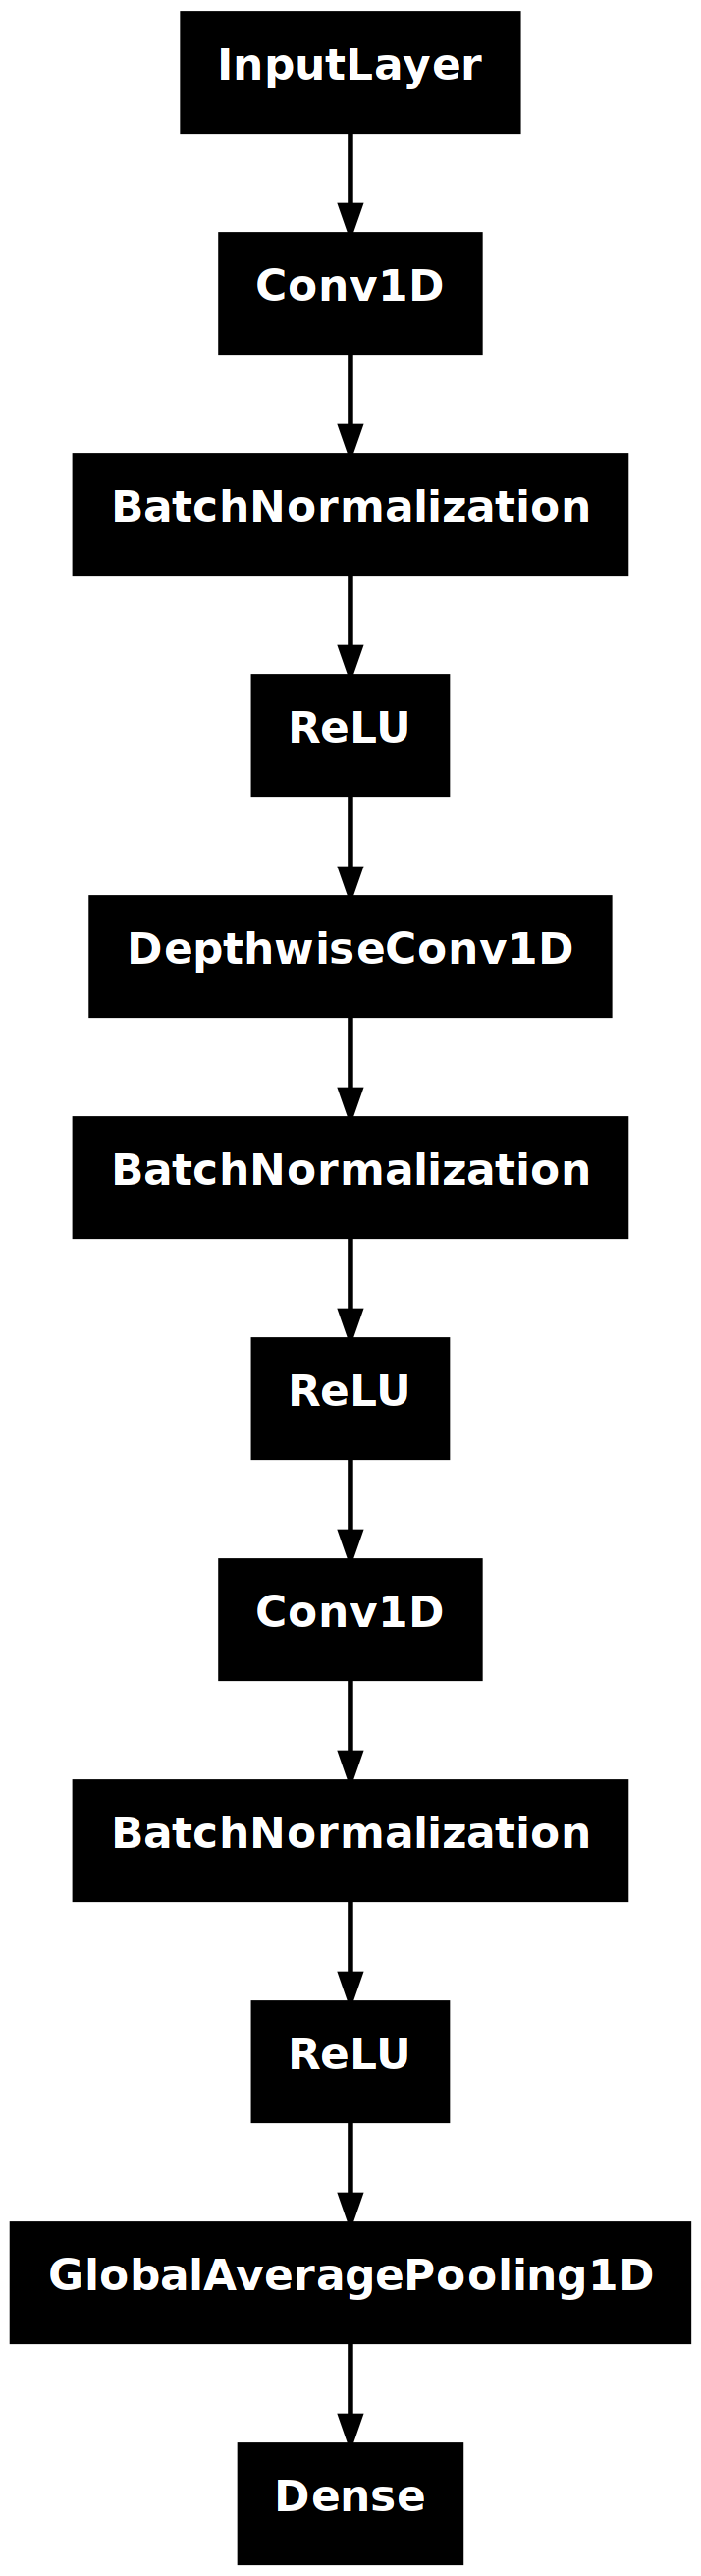

In [16]:
input_shape = (X_train.shape[1], 1)
num_classes = 15
model = mobilenet_1d(input_shape=input_shape, num_classes=num_classes)
model.summary()
plot_model(model)

In [17]:
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = {
    np.int64(cls): weight for cls, weight in zip(np.unique(y_train), class_weights)
}
sample_weights = np.array([class_weights_dict[label] for label in y_train])


In [18]:
train_start_time = time.time()
# Train the model
# history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=6, batch_size=32, sample_weight=sample_weights)
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=6, batch_size=32)

# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=32)
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

Epoch 1/6


I0000 00:00:1745660879.819960   17455 service.cc:146] XLA service 0x7f1c08010470 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1745660879.819989   17455 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce RTX 2060 with Max-Q Design, Compute Capability 7.5
2025-04-26 13:17:59.859598: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-04-26 13:18:00.023086: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 90101


   96/42557 ━━━━━━━━━━━━━━━━━━━━ 1:15 2ms/step - accuracy: 0.4909 - loss: 2.0962

I0000 00:00:1745660882.821063   17455 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


42557/42557 ━━━━━━━━━━━━━━━━━━━━ 121s 3ms/step - accuracy: 0.9219 - loss: 0.2106 - val_accuracy: 0.9460 - val_loss: 0.1333
Epoch 2/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 93s 2ms/step - accuracy: 0.9484 - loss: 0.1141 - val_accuracy: 0.9442 - val_loss: 0.1439
Epoch 3/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 95s 2ms/step - accuracy: 0.9524 - loss: 0.1044 - val_accuracy: 0.9334 - val_loss: 0.1626
Epoch 4/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 99s 2ms/step - accuracy: 0.9543 - loss: 0.0985 - val_accuracy: 0.9545 - val_loss: 0.1239
Epoch 5/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 101s 2ms/step - accuracy: 0.9560 - loss: 0.0946 - val_accuracy: 0.9559 - val_loss: 0.1121
Epoch 6/6
42557/42557 ━━━━━━━━━━━━━━━━━━━━ 99s 2ms/step - accuracy: 0.9567 - loss: 0.0923 - val_accuracy: 0.9341 - val_loss: 0.1656
12160/12160 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - accuracy: 0.9338 - loss: 0.1574
Test Loss: 0.1575
Test Accuracy: 0.9334
Training time: 609.14 seconds
Testing time: 19.19 seconds


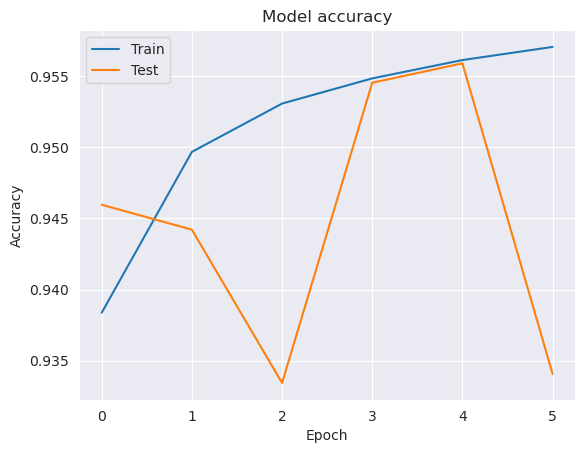

In [25]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

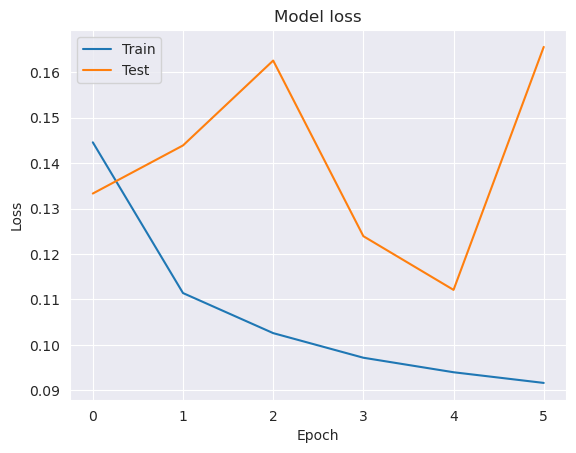

In [20]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [21]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

12160/12160 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step


In [22]:
y_pred_classes = np.argmax(y_pred, axis=1)

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

                       precision    recall  f1-score   support

               Normal       1.00      1.00      1.00    280115
                 MITM       0.00      0.00      0.00        69
            Uploading       0.36      0.81      0.49      7588
           Ransomware       0.33      0.94      0.49      2012
        SQL_injection       0.62      0.41      0.49     10041
            DDoS_HTTP       0.74      0.95      0.83      9620
             DDoS_TCP       0.82      0.93      0.87     10052
             Password       0.64      0.24      0.35      9869
        Port_Scanning       1.00      0.48      0.65      3985
Vulnerability_scanner       0.93      0.85      0.89      9985
             Backdoor       0.91      0.35      0.51      4883
                  XSS       0.45      0.16      0.24      3073
       Fingerprinting       0.27      0.51      0.35       171
             DDoS_UDP       1.00      1.00      1.00     24316
            DDoS_ICMP       1.00      0.98      0.99  

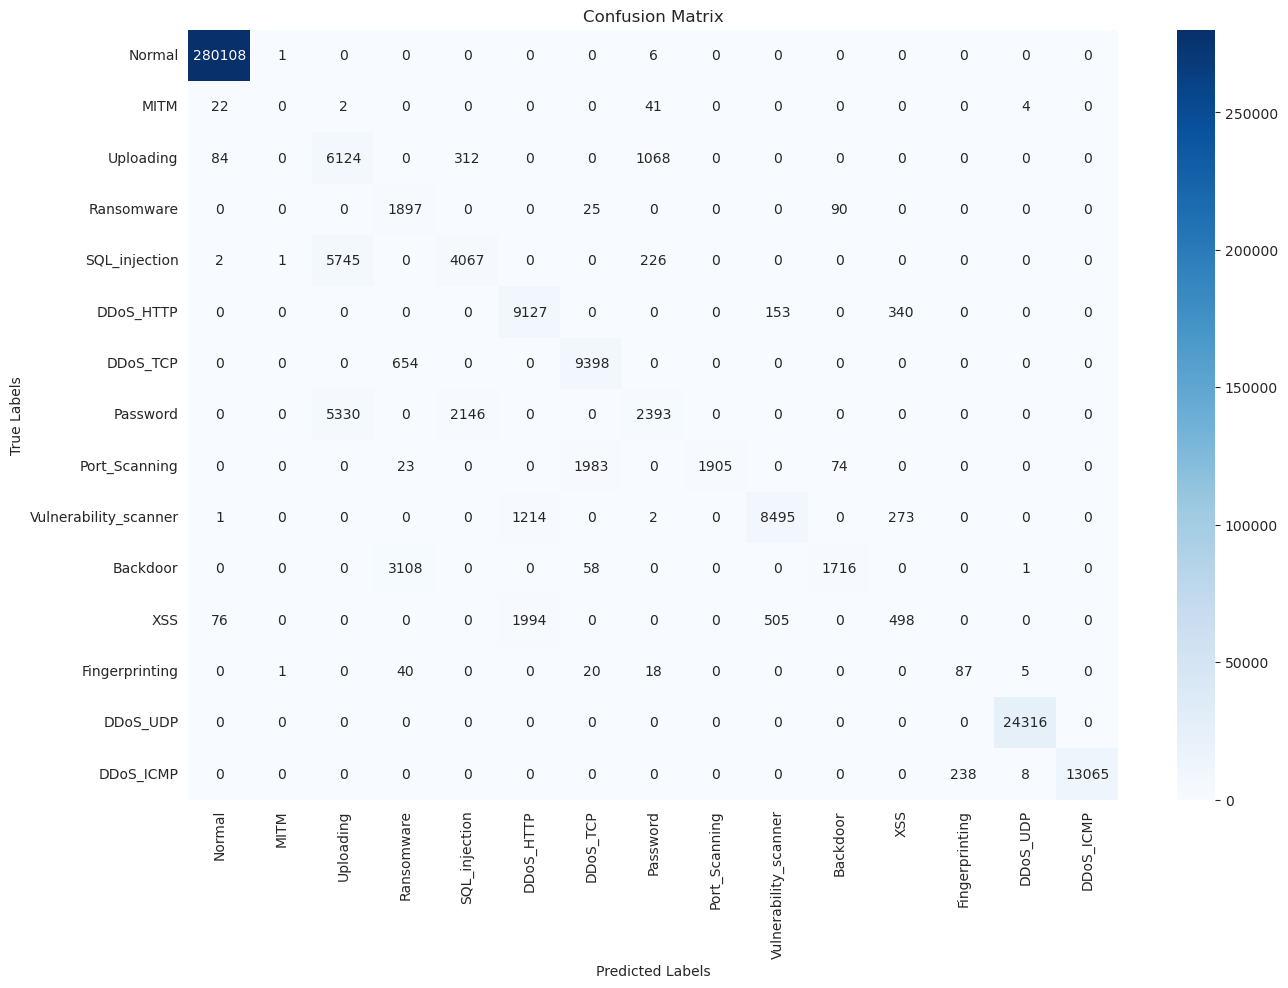

In [23]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

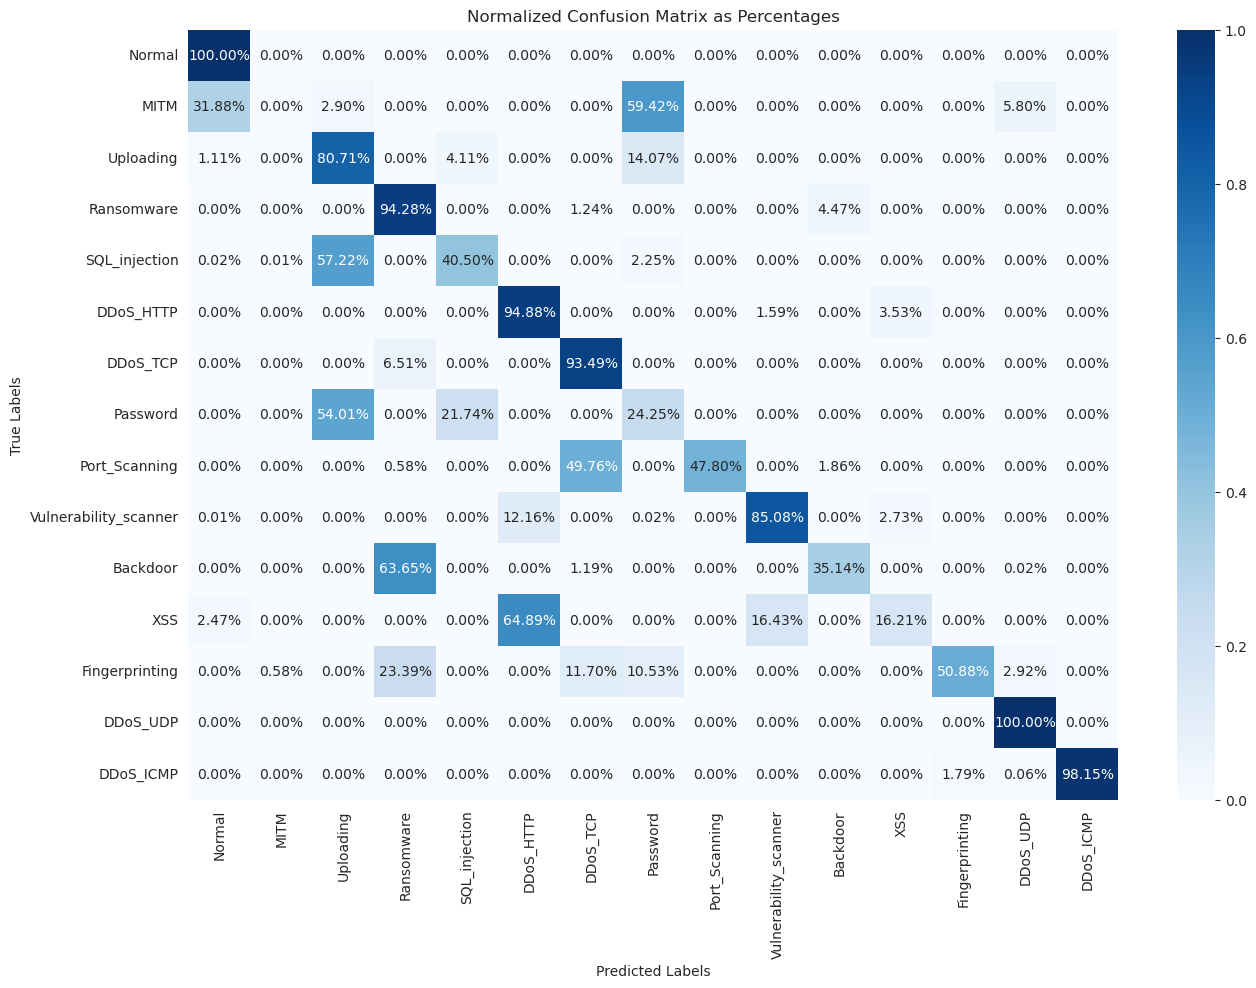

In [24]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')